# Effects

A passage on a night card where five words carry their meaning: smoke curls, metal shines, wind blows,
sparks burn and snow falls. Each effect styles a range of the text, so the words stay real, selectable
text. Beside the passage the same effects dress a logo and two buttons, sized to each shape. Every effect
animates with SMIL.

In [1]:
import functools

from IPython import display as ipy
import svgwriter as svg

from animations import twinkle
from components import card

The project's theme applies to every drawing below, as it does when the project builds.

In [2]:
project = svg.Project.load()
theme = svg.Theme.load(project.config.theme)

In [3]:
LINES = (
    "...into the cold night, and Smoke curled around",
    "his Metal scales. A bitter Wind carried sparks",
    "across the Snow plains, where an...",
)
EFFECT_NAMES = list(svg.effects.__all__)
INSET = 16          # card edge to page edge
LEFT = 64           # first letter of each line
FIRST = 108         # baseline of the first line
LEADING = 54        # baseline to baseline
PANEL = 940         # centre of the logo and buttons beside the passage
LOGO = (110, 44)    # logo centre height and radius
LOGO_INNER = 0.55   # inner radius of the logo star, as a share of its radius
BUTTONS = (("Play", -62), ("Stop", 62))  # label and centre offset of each button
BUTTON = (100, 40, 208)  # width, height and centre height of the buttons
LABEL_INK = "#0f172a"  # button labels, dark on the lit buttons

`line[start:end].effect(name)` moves that range of a line onto a copy just above it, so the effect's
filter reaches only those letters while the line keeps its spacing. Each word has a dropdown, so
`svgwriter preview` (or `svg.explore` in a notebook) can swap its effect.

In [4]:
def effect_choice(label: str, value: str) -> svg.widgets.Dropdown:
    """The dropdown that picks the effect of *label*, starting at *value*."""
    return svg.widgets.Dropdown(EFFECT_NAMES, value=value, label=label)


def badges(doc: svg.Document, logo: str, button: str) -> None:
    """The logo and the two buttons beside the passage, each with an effect sized to its shape."""
    center, radius = LOGO
    doc.add(svg.paths.star(PANEL, center, radius, points=6, inner=radius * LOGO_INNER)).effect(logo)
    width, height, middle = BUTTON
    for label, offset in BUTTONS:
        doc.rect(PANEL + offset - width / 2, middle - height / 2, width, height, rx=height / 2,
                 stroke_width=2).effect(button)
        doc.text(label, x=PANEL + offset, y=middle + 6, font_size=18, text_anchor="middle", fill=LABEL_INK)


@svg.widgets.controls(smoke=effect_choice("Smoke", "smoke"), metal=effect_choice("Metal", "metal"),
                      wind=effect_choice("Wind", "wind"), sparks=effect_choice("sparks", "fire"),
                      snow=effect_choice("Snow", "snow"), logo=effect_choice("logo", "metal"),
                      button=effect_choice("buttons", "neon"))
def passage(doc: svg.Document, *, smoke: str = "smoke", metal: str = "metal", wind: str = "wind",
            sparks: str = "fire", snow: str = "snow", logo: str = "metal", button: str = "neon") -> svg.Document:
    """Draw the card, the passage with the chosen effect on each of the five words, the logo and the buttons."""
    box = doc.root.get("viewBox")
    sky = card(box.width, box.height, inset=INSET, caption="svg.effects")
    doc += sky
    sky.children[2].animate.apply(twinkle)
    effects = {"Smoke": smoke, "Metal": metal, "Wind": wind, "sparks": sparks, "Snow": snow}
    for row, words in enumerate(LINES):
        line = doc.text(words, x=LEFT, y=FIRST + row * LEADING).as_role("text")
        for word, effect in effects.items():
            if word in words:
                start = words.index(word)
                line[start:start + len(word)].effect(effect)
    badges(doc, logo, button)
    return doc

Every control of `passage` becomes an input: in a running notebook (with the `widget` extra) this panel redraws the drawing as you change them. A saved notebook cannot keep live widgets, so the stills below show other values.

In [5]:
def in_project(function):
    @functools.wraps(function)
    def draw(doc, **values):
        size = project.config.size
        sheet = svg.Document(*size, theme=theme) if isinstance(size, tuple) else svg.Document(size=size, theme=theme)
        with theme:
            result = function(sheet, **values)
        return sheet if result is None else result

    return draw


def show(function, **values):
    ipy.display(ipy.SVG(data=in_project(function)(None, **values).to_string()))


svg.explore(in_project(passage))

The same function for other control values.

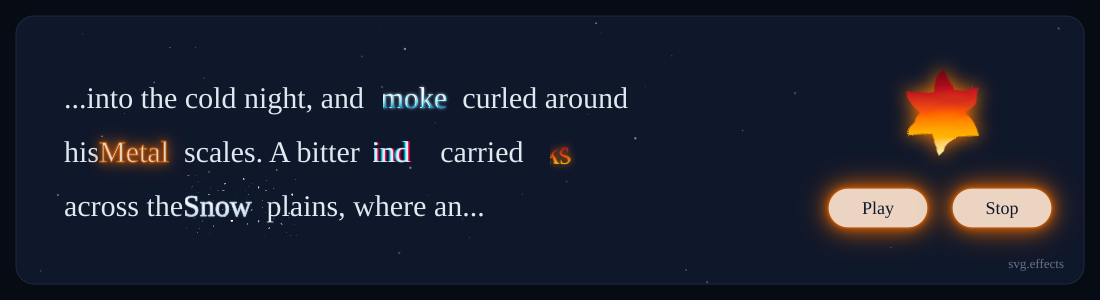

In [6]:
show(passage, **{'smoke': 'ice', 'metal': 'neon', 'wind': 'glitch', 'logo': 'fire'})

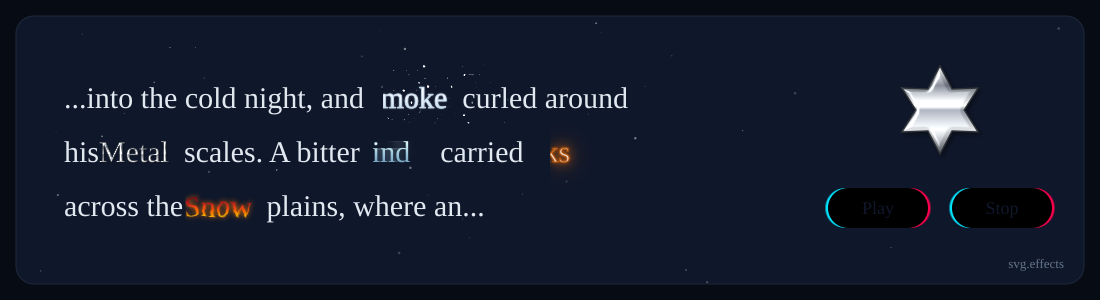

In [7]:
show(passage, **{'sparks': 'neon', 'snow': 'fire', 'smoke': 'snow', 'button': 'glitch'})

`project.build` writes the outputs listed in `svgwriter.toml` (here only the SVG, which keeps animations as SMIL) and the notebook shows each one.

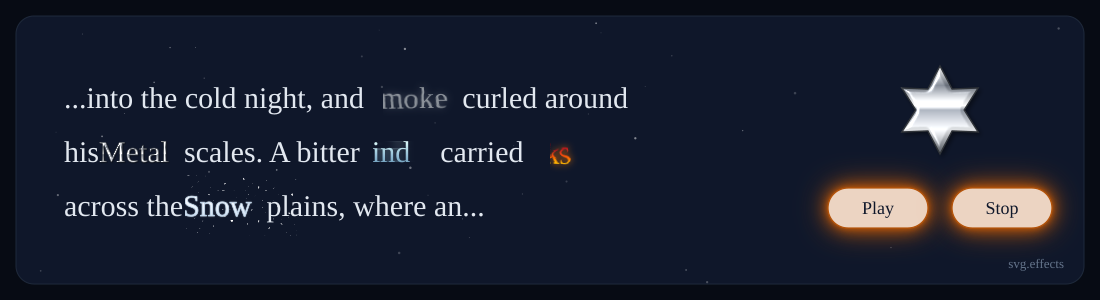

In [8]:
for path in project.build(["svg"]):
    ipy.display(ipy.SVG(filename=str(path)))